# Autonomous Data-Science Agent

**Goal.** Given a dataset and a target column, an agent team profiles the data, plans experiments, trains and cross-validates models, critiques the results, iterates, and writes a model card. Selection happens on cross-validation, and the chosen model is scored once on a held-out test set.

| Agent | Type | Responsibility |
|---|---|---|
| **Profiler** | Tool | Column types, missing values, class balance, likely ID or leakage columns |
| **Planner** | LLM, validated output | Chooses the metric, preprocessing and 3–4 candidate models from a **registry of allowed components** |
| **Experimenter** | Tool | Builds scikit-learn pipelines from the plan and runs stratified 5-fold cross-validation |
| **Critic** | LLM + rules | Reviews the leaderboard (scores, train–CV gap, fit time) and proposes one refinement round from allowed hyperparameter grids |
| **Reporter** | Template + LLM | Writes a model card. Comparisons and numbers come from code; the LLM adds a qualitative limitation, which is checked to contain no numbers |

**Safety by design.** The language model never writes or runs code. It can only select names and settings from a fixed registry, and those selections are validated before execution. This removes the arbitrary-code-execution risk that comes with "code-interpreter" agents.

**Datasets (public and openly licensed)**

| Dataset | Task | Licence |
|---|---|---|
| Palmer Penguins (Horst, Hill & Gorman, 2020) | 3-class species classification, with missing values and categorical features | CC0 |
| Breast Cancer Wisconsin (Diagnostic), bundled with scikit-learn | binary classification | CC BY 4.0 (UCI) |
| Diabetes (Efron et al., 2004), bundled with scikit-learn | regression | distributed with scikit-learn (BSD-3) |

## 1. Setup

In [1]:
import os
os.environ["TQDM_DISABLE"] = "1"   # keep notebook output readable
import time, warnings, json, re
from pathlib import Path
from typing import Literal, Optional, TypedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from pydantic import BaseModel, Field, field_validator
from langgraph.graph import StateGraph, END
from IPython.display import Markdown, display
from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.svm import SVC, SVR
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import get_scorer

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
SEED = 42
DATA = Path("data"); DATA.mkdir(exist_ok=True)

### LLM provider (shared `agentkit` package)

All agents call language models through `agentkit` (in `Agentic AI/agentkit/`), a provider-independent layer. **No code changes are needed to switch providers**: put keys in a `.env` file (see `.env.example`) and re-run.

| Configuration found | Provider used |
|---|---|
| `OPENAI_API_KEY` | OpenAI (`gpt-4.1-mini` by default, or `OPENAI_MODEL`; `OPENAI_BASE_URL` for any OpenAI-compatible server) |
| `GOOGLE_API_KEY` or `GEMINI_API_KEY` | Google Gemini (`gemini-3.1-flash-lite` by default, or `GEMINI_MODEL`) |
| an Ollama server with a model pulled | Ollama (best installed model, or `OLLAMA_MODEL`) |
| nothing (offline default) | a local Hugging Face model: the best Apache-2.0 Qwen3 model that fits in free memory (8B / 4B / 1.7B / 0.6B) |

`LLM_PROVIDER` forces a choice. Outputs are validated against Pydantic schemas, using native JSON mode where the provider supports it, and tools use each provider's native tool calling. Transient errors are retried with backoff, and an API failure falls back to the local model; the fallback is logged and labelled. **Caching is off by default, so every response below was generated live in this run.** With `LLM_CACHE=readwrite` or `replay`, every cached response is flagged as `[CACHE REPLAY]` and counted separately. Each call is recorded in `outputs/llm_calls.jsonl`, and the last cell prints a provenance report.

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().resolve().parent))      # Agentic AI/, which holds the shared agentkit package
from agentkit import LLM, configure_logging
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
log = configure_logging(OUT)

In [3]:
llm = LLM()
print(llm.describe())

Provider: huggingface   Model: Qwen/Qwen3-1.7B
Why: no API key and no Ollama server: running offline with a local Hugging Face model; best Apache-2.0 model that fits 7.4 GB free cpu memory
API keys: OpenAI not set, Gemini not set | cache: off (every call is live) | fallback to local: on
.env files loaded: none


## 2. Datasets

In [4]:
PENGUINS_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
penguins_path = DATA / "penguins.csv"
if not penguins_path.exists():
    pd.read_csv(PENGUINS_URL).to_csv(penguins_path, index=False)
penguins = pd.read_csv(penguins_path)
bc = load_breast_cancer(as_frame=True).frame.rename(columns={"target": "diagnosis"})
diabetes = load_diabetes(as_frame=True).frame.rename(columns={"target": "progression"})

DATASETS = {
    "penguins": {"df": penguins, "target": "species", "task": "classification", "description": "Penguin species from body measurements, island and sex"},
    "breast_cancer": {"df": bc, "target": "diagnosis", "task": "classification", "description": "Malignant vs benign tumours from cell-nucleus measurements"},
    "diabetes": {"df": diabetes, "target": "progression", "task": "regression", "description": "Disease progression one year after baseline from 10 clinical variables"},
}
pd.DataFrame({k: {"rows": len(v["df"]), "columns": v["df"].shape[1] - 1, "task": v["task"], "missing cells": int(v["df"].isna().sum().sum())}
              for k, v in DATASETS.items()}).T

,rows,columns,task,missing cells
penguins,344,6,classification,19
breast_cancer,569,30,classification,0
diabetes,442,10,regression,0


## 3. The component registry: what the agent is allowed to use

Every model and preprocessing option the planner can choose is listed here with a fixed constructor and a small hyperparameter grid. The planner's output is validated against these names, so it cannot reference anything outside the registry.

In [5]:
MODELS = {
    "classification": {
        "logistic_regression": (lambda **p: LogisticRegression(max_iter=2000, **p), {"C": [1.0, 0.1, 10.0]}),
        "random_forest": (lambda **p: RandomForestClassifier(random_state=SEED, n_jobs=-1, **p), {"n_estimators": [200, 500], "max_depth": [None, 8]}),
        "hist_gradient_boosting": (lambda **p: HistGradientBoostingClassifier(random_state=SEED, **p), {"learning_rate": [0.1, 0.05], "max_depth": [None, 4]}),
        "svm_rbf": (lambda **p: SVC(probability=True, random_state=SEED, **p), {"C": [1.0, 0.5, 5.0], "gamma": ["scale"]}),
        "knn": (lambda **p: KNeighborsClassifier(**p), {"n_neighbors": [5, 15]}),
    },
    "regression": {
        "ridge": (lambda **p: Ridge(**p), {"alpha": [1.0, 0.1, 10.0]}),
        "lasso": (lambda **p: Lasso(max_iter=10000, **p), {"alpha": [0.1, 0.01, 1.0]}),
        "random_forest": (lambda **p: RandomForestRegressor(random_state=SEED, n_jobs=-1, **p), {"n_estimators": [200, 500], "max_depth": [None, 8]}),
        "hist_gradient_boosting": (lambda **p: HistGradientBoostingRegressor(random_state=SEED, **p), {"learning_rate": [0.1, 0.05], "max_depth": [None, 4]}),
        "svr_rbf": (lambda **p: SVR(**p), {"C": [1.0, 10.0, 50.0]}),
        "knn": (lambda **p: KNeighborsRegressor(**p), {"n_neighbors": [5, 15]}),
    },
}
METRICS = {"classification": ["accuracy", "balanced_accuracy", "f1_macro", "roc_auc"], "regression": ["r2", "neg_root_mean_squared_error", "neg_mean_absolute_error"]}
IMPUTERS = ["median", "mean", "most_frequent"]
# The first value in every grid is the default. Configurations are always fully specified, so duplicates are detectable.
def pkey(params: dict) -> str:
    return json.dumps(params, sort_keys=True)

## 4. Tools

### 4.1 Profiler

In [6]:
def profile(df: pd.DataFrame, target: str) -> dict:
    X = df.drop(columns=[target])
    y = df[target]
    num = X.select_dtypes(include="number").columns.tolist()
    cat = [c for c in X.columns if c not in num]
    suspects = []
    for c in X.columns:
        if X[c].nunique() == len(X) and (c in cat or "id" in c.lower()):
            suspects.append(f"{c}: unique per row (identifier)")
        if c in num and y.dtype.kind in "if" and abs(np.corrcoef(X[c].fillna(X[c].median()), y.fillna(y.median()))[0, 1]) > 0.98:
            suspects.append(f"{c}: near-perfect correlation with target (possible leakage)")
    prof = {"rows": len(df), "numeric_features": num, "categorical_features": cat,
            "missing_by_column": {c: int(v) for c, v in df.isna().sum().items() if v > 0},
            "target_missing": int(y.isna().sum()), "suspect_columns": suspects}
    if y.dtype.kind not in "if" or y.nunique() <= 10:
        prof["class_balance"] = {str(k): round(float(v), 3) for k, v in y.value_counts(normalize=True).items()}
    else:
        prof["target_summary"] = {k: round(float(v), 2) for k, v in y.describe()[["mean", "std", "min", "max"]].items()}
    return prof

print(json.dumps(profile(penguins, "species"), indent=1))

{
 "rows": 344,
 "numeric_features": [
  "bill_length_mm",
  "bill_depth_mm",
  "flipper_length_mm",
  "body_mass_g"
 ],
 "categorical_features": [
  "island",
  "sex"
 ],
 "missing_by_column": {
  "bill_length_mm": 2,
  "bill_depth_mm": 2,
  "flipper_length_mm": 2,
  "body_mass_g": 2,
  "sex": 11
 },
 "target_missing": 0,
 "suspect_columns": [],
 "class_balance": {
  "Adelie": 0.442,
  "Gentoo": 0.36,
  "Chinstrap": 0.198
 }
}


### 4.2 Experimenter

Turns a validated plan into scikit-learn pipelines (imputation, scaling and one-hot encoding inside the cross-validation folds, so nothing leaks from validation folds) and runs 5-fold cross-validation on the training split.

In [7]:
def build_pipeline(task, model_name, params, num_cols, cat_cols, impute, scale):
    num_steps = [("impute", SimpleImputer(strategy=impute))] + ([("scale", StandardScaler())] if scale else [])
    pre = ColumnTransformer([("num", Pipeline(num_steps), num_cols),
                             ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                               ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])
    ctor, _ = MODELS[task][model_name]
    return Pipeline([("pre", pre), ("model", ctor(**params))])

def run_experiments(task, X, y, candidates, metric, impute, scale, prof):
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED) if task == "classification" else KFold(5, shuffle=True, random_state=SEED)
    rows = []
    for cand in candidates:
        pipe = build_pipeline(task, cand["model"], cand["params"], prof["numeric_features"], prof["categorical_features"], impute, scale)
        scoring = metric if not (metric == "roc_auc" and y.nunique() > 2) else "roc_auc_ovr"
        t0 = time.time()
        try:
            cvr = cross_validate(pipe, X, y, cv=cv, scoring=scoring, return_train_score=True, error_score="raise")
            rows.append({"model": cand["model"], "params": pkey(cand["params"]), "cv_mean": cvr["test_score"].mean(),
                         "cv_std": cvr["test_score"].std(), "train_mean": cvr["train_score"].mean(), "fit_seconds": time.time() - t0, "error": None})
        except Exception as e:
            log.warning("experiment failed: %s %s: %s", cand["model"], cand["params"], e)
            rows.append({"model": cand["model"], "params": pkey(cand["params"]), "cv_mean": np.nan, "cv_std": np.nan,
                         "train_mean": np.nan, "fit_seconds": time.time() - t0, "error": str(e)[:200]})
    df = pd.DataFrame(rows)
    df["gap"] = df.train_mean - df.cv_mean
    return df

## 5. Agents

### 5.1 Planner, with output validated against the registry

In [8]:
class Candidate(BaseModel):
    model: str
    params: dict = Field(default_factory=dict)

class ExperimentPlan(BaseModel):
    metric: str
    impute: str = "median"
    scale: bool = True
    candidates: list
    rationale: str = ""

def validate_plan(plan: ExperimentPlan, task: str) -> ExperimentPlan:
    """Keep only registry components; clamp hyperparameters to the allowed grid; fill sensible defaults."""
    metric = plan.metric if plan.metric in METRICS[task] else METRICS[task][0 if task == "regression" else 2]
    impute = plan.impute if plan.impute in IMPUTERS else "median"
    cands, seen = [], set()
    for c in plan.candidates:
        c = c if isinstance(c, dict) else {"model": str(c)}
        name = str(c.get("model", "")).strip().lower().replace(" ", "_").replace("-", "_")
        if name not in MODELS[task] or name in seen:
            continue
        grid = MODELS[task][name][1]
        given = c.get("params") or {}
        params = {k: (given[k] if given.get(k, object()) in grid[k] else vals[0]) for k, vals in grid.items()}
        cands.append({"model": name, "params": params})
        seen.add(name)
    if len(cands) < 2:   # never run an empty or single-model search
        for name in list(MODELS[task])[:3]:
            if name not in seen:
                cands.append({"model": name, "params": {k: v[0] for k, v in MODELS[task][name][1].items()}}); seen.add(name)
    return ExperimentPlan(metric=metric, impute=impute, scale=bool(plan.scale), candidates=cands[:4], rationale=plan.rationale[:400])

def planner(name: str, spec: dict, prof: dict) -> ExperimentPlan:
    task = spec["task"]
    system = ("You are a senior data scientist planning experiments. Reply with JSON only, matching:\n"
              '{"metric": str, "impute": str, "scale": bool, "candidates": [{"model": str, "params": {}}], "rationale": str}\n'
              f"Allowed metrics: {METRICS[task]}. Allowed impute: {IMPUTERS}. Allowed models and hyperparameter grids: "
              f"{json.dumps({k: v[1] for k, v in MODELS[task].items()})}. Choose 3-4 diverse candidates.")
    user = f"Dataset '{name}': {spec['description']}. Task: {task}. Target: {spec['target']}.\nProfile: {json.dumps(prof)}"
    try:
        raw = llm.structured([{"role": "system", "content": system}, {"role": "user", "content": user}], ExperimentPlan, max_tokens=300)
    except RuntimeError as e:
        log.warning("planner fell back to defaults: %s", e)
        raw = ExperimentPlan(metric="", candidates=[])
    return validate_plan(raw, task)

### 5.2 Critic

The critic combines **rules** and the **LLM**. Rules flag hard problems: failed runs, a train–CV gap above 0.10 (overfitting) and very slow models. The LLM reads the leaderboard and the flags, then proposes refinements: other grid values for the best one or two models. Its proposals are validated against the registry like the planner's.

In [9]:
class Critique(BaseModel):
    assessment: str
    refinements: list = Field(default_factory=list)

def critic(task: str, leaderboard: pd.DataFrame, metric: str) -> tuple:
    flags = []
    for r in leaderboard.itertuples():
        if isinstance(r.error, str) and r.error:
            flags.append(f"{r.model} failed: {r.error[:80]}")
        elif r.gap > 0.10:
            flags.append(f"{r.model} {r.params} may overfit (train-CV gap {r.gap:.3f})")
    board = leaderboard[["model", "params", "cv_mean", "cv_std", "gap", "fit_seconds"]].round(4).to_string(index=False)
    grids = json.dumps({k: v[1] for k, v in MODELS[task].items()})
    system = ("You review ML experiment results. Reply with JSON only: "
              '{"assessment": "<2 sentences>", "refinements": [{"model": str, "params": {}}]}. '
              f"Propose up to 3 refinements using ONLY these grids: {grids}. Prefer refining the best models; do not repeat a configuration already tried.")
    top = leaderboard.sort_values("cv_mean", ascending=False).iloc[0]
    user = (f"Metric: {metric} (higher is better).\nLeaderboard:\n{board}\nBest so far: {top.model} {top.params} with CV {top.cv_mean:.4f}.\n"
            f"Rule-based flags: {flags or 'none'}")
    try:
        crit = llm.structured([{"role": "system", "content": system}, {"role": "user", "content": user}], Critique, max_tokens=250)
    except RuntimeError:
        crit = Critique(assessment="Critic unavailable; refining the best model with alternative grid values.", refinements=[])
    # grounding check: an assessment that quotes numbers not on the leaderboard is replaced by a factual summary
    board_nums = {round(float(x), d) for x in leaderboard[["cv_mean", "cv_std", "gap", "fit_seconds"]].to_numpy().ravel() if x == x for d in (2, 3, 4)}
    quoted = [float(t) for t in re.findall(r"(?<![\w.])-?\d+\.\d+", crit.assessment)]
    if any(round(q, len(str(q).split(".")[1])) not in board_nums for q in quoted):
        log.info("critic assessment rejected (ungrounded numbers): %s", crit.assessment)
        crit = crit.model_copy(update={"assessment": f"[LLM assessment rejected: ungrounded numbers] Best so far is {top.model} {top.params} "
                                                     f"(CV {top.cv_mean:.4f} ± {top.cv_std:.4f}); {len(flags)} rule-based flag(s)."})
    tried = set(zip(leaderboard.model, leaderboard.params))
    refined = validate_plan(ExperimentPlan(metric=metric, candidates=crit.refinements or []), task).candidates if crit.refinements else []
    refined = [c for c in refined if (c["model"], pkey(c["params"])) not in tried]
    if not refined:   # deterministic fallback: explore the best model's grid
        top = leaderboard.sort_values("cv_mean", ascending=False).iloc[0]
        best, base = top.model, json.loads(top.params)
        for k, vals in MODELS[task][best][1].items():
            for v in vals:
                c = {"model": best, "params": {**base, k: v}}
                if (best, pkey(c["params"])) not in tried and c not in refined:
                    refined.append(c)
        refined = refined[:3]
    return crit.assessment, flags, refined

### 5.3 LangGraph workflow

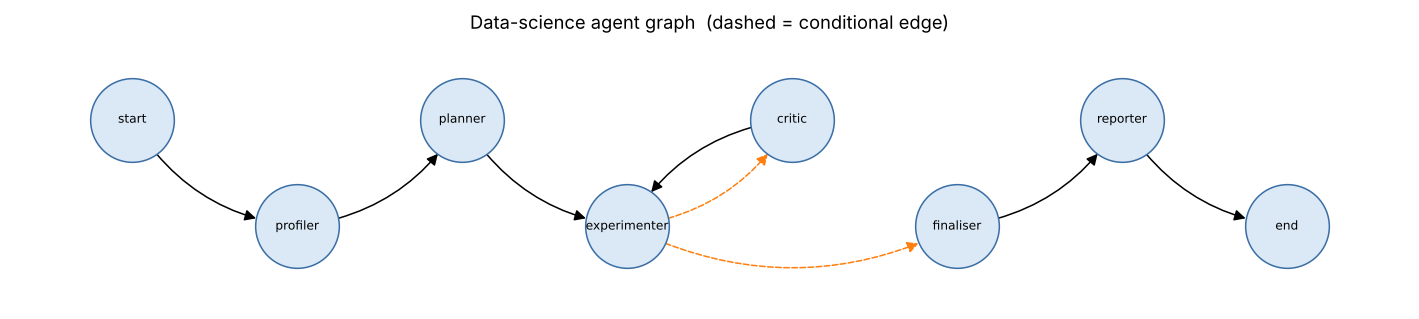

In [10]:
class DSState(TypedDict, total=False):
    name: str
    spec: dict
    X_train: pd.DataFrame
    y_train: pd.Series
    X_test: pd.DataFrame
    y_test: pd.Series
    profile: dict
    plan: ExperimentPlan
    leaderboard: pd.DataFrame
    round: int
    critiques: list
    pending: list
    final: dict
    card: str
    trace: list

MAX_ROUNDS = 2

def profile_node(s):
    spec = s["spec"]
    df = spec["df"].dropna(subset=[spec["target"]])
    X, y = df.drop(columns=[spec["target"]]), df[spec["target"]]
    strat = y if spec["task"] == "classification" else None
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=strat)
    prof = profile(pd.concat([X_tr, y_tr], axis=1), spec["target"])
    return {"X_train": X_tr, "y_train": y_tr, "X_test": X_te, "y_test": y_te, "profile": prof, "round": 0, "critiques": [],
            "trace": [("profiler", f"{prof['rows']} training rows, {len(prof['numeric_features'])} numeric / {len(prof['categorical_features'])} categorical, missing {prof['missing_by_column'] or 'none'}")]}

def plan_node(s):
    plan = planner(s["name"], s["spec"], s["profile"])
    return {"plan": plan, "pending": plan.candidates,
            "trace": s["trace"] + [("planner", f"metric={plan.metric}, impute={plan.impute}, scale={plan.scale}, models={[c['model'] for c in plan.candidates]}")]}

def experiment_node(s):
    p = s["plan"]
    new = run_experiments(s["spec"]["task"], s["X_train"], s["y_train"], s["pending"], p.metric, p.impute, p.scale, s["profile"])
    new["round"] = s["round"] + 1
    board = pd.concat([s.get("leaderboard"), new], ignore_index=True) if s.get("leaderboard") is not None else new
    best = board.sort_values("cv_mean", ascending=False).iloc[0]
    return {"leaderboard": board, "round": s["round"] + 1,
            "trace": s["trace"] + [("experimenter", f"round {s['round'] + 1}: {len(new)} runs; best so far {best.model} {best.params} CV {p.metric}={best.cv_mean:.4f}")]}

def critic_node(s):
    assessment, flags, refined = critic(s["spec"]["task"], s["leaderboard"], s["plan"].metric)
    return {"pending": refined, "critiques": s["critiques"] + [{"assessment": assessment, "flags": flags, "refinements": refined}],
            "trace": s["trace"] + [("critic", f"{assessment[:160]} | refinements: {[(c['model'], c['params']) for c in refined]}")]}

def route_after_experiment(s):
    return "critic" if s["round"] < MAX_ROUNDS else "finalise"

def finalise_node(s):
    """Select by CV (never by test), refit on the full training split, score once on the held-out test set."""
    spec, p = s["spec"], s["plan"]
    board = s["leaderboard"].dropna(subset=["cv_mean"])
    # deterministic tie-break: higher CV mean, then lower CV std, then registry order (simpler models are listed first)
    order = {m: i for i, m in enumerate(MODELS[spec["task"]])}
    board = board.assign(_cv=board.cv_mean.round(6), _std=board.cv_std.round(6), _order=board.model.map(order))
    best = board.sort_values(["_cv", "_std", "_order", "params"], ascending=[False, True, True, True]).iloc[0]
    pipe = build_pipeline(spec["task"], best.model, json.loads(best.params), s["profile"]["numeric_features"],
                          s["profile"]["categorical_features"], p.impute, p.scale).fit(s["X_train"], s["y_train"])
    metric = p.metric if not (p.metric == "roc_auc" and s["y_train"].nunique() > 2) else "roc_auc_ovr"
    scorer = get_scorer(metric)
    test_score = scorer(pipe, s["X_test"], s["y_test"])
    # reference points: a trivial model and an untuned linear model on the same split and preprocessing
    dummy = (DummyClassifier(strategy="most_frequent") if spec["task"] == "classification" else DummyRegressor()).fit(s["X_train"].select_dtypes("number").fillna(0), s["y_train"])
    dummy_score = scorer(dummy, s["X_test"].select_dtypes("number").fillna(0), s["y_test"])
    base_name = "logistic_regression" if spec["task"] == "classification" else "ridge"
    base = build_pipeline(spec["task"], base_name, {k: v[0] for k, v in MODELS[spec["task"]][base_name][1].items()}, s["profile"]["numeric_features"], s["profile"]["categorical_features"], "median", True).fit(s["X_train"], s["y_train"])
    final = {"model": best.model, "params": best.params, "metric": metric, "cv_mean": best.cv_mean, "cv_std": best.cv_std,
             "test_score": test_score, "dummy_test": dummy_score, "baseline_model": base_name, "baseline_test": scorer(base, s["X_test"], s["y_test"])}
    return {"final": final, "trace": s["trace"] + [("finaliser", f"selected {best.model} {best.params}; test {metric}={test_score:.4f}")]}

def report_node(s):
    f, p, prof = s["final"], s["plan"], s["profile"]
    # Comparisons are written by code, so every number and every "better/worse" is correct by construction.
    d_base, d_dummy = f["test_score"] - f["baseline_test"], f["test_score"] - f["dummy_test"]
    facts = [f"Selected `{f['model']}` {f['params']} because it had the best 5-fold CV {f['metric']} ({f['cv_mean']:.4f} ± {f['cv_std']:.4f}) "
             f"of {len(s['leaderboard'])} configurations tried.",
             f"On the held-out test set it scored {f['test_score']:.4f}: "
             + (f"{abs(d_base):.4f} {'above' if d_base > 0 else 'below'} the untuned {f['baseline_model']} ({f['baseline_test']:.4f})" if abs(d_base) >= 5e-5
                else f"the same as the untuned {f['baseline_model']}")
             + f", and {d_dummy:.4f} above the trivial baseline ({f['dummy_test']:.4f})."]
    if d_base < 0 and abs(d_base) <= 2 * f["cv_std"]:
        facts.append(f"The gap to the untuned baseline is within two CV standard deviations ({2 * f['cv_std']:.4f}), so it is not evidence that either is better.")
    if d_base < 0 and s["spec"]["task"] == "classification":
        n = len(s["y_test"])
        facts.append(f"With {n} test rows, one prediction moves the test score by roughly {1 / n:.4f}, so small test-set gaps are within sampling noise; "
                     f"selection relies on cross-validation, which averages over more data.")
    # The LLM adds one qualitative limitation; it must contain no digits (numbers belong to the code-written lines above).
    msgs = [{"role": "system", "content": "In ONE sentence and WITHOUT any numbers or digits, state the most important limitation or next step for this model. "
                                           "Consider dataset size, the small search space, feature engineering and interpretability."},
            {"role": "user", "content": f"Dataset: {s['spec']['description']}; {prof['rows']} training rows; selected {f['model']}; task {s['spec']['task']}."}]
    limitation = llm.chat(msgs, max_tokens=80).strip().split("\n")[0]
    if re.search(r"\d", limitation) or len(limitation) < 20:
        limitation = "Small dataset and a deliberately small search space: confirm the choice with repeated cross-validation before relying on it."
    interpretation = "\n".join(f"- {x}" for x in facts) + f"\n- Limitation (LLM-written, checked to contain no numbers): {limitation}"
    top = s["leaderboard"].sort_values("cv_mean", ascending=False).head(5)[["model", "params", "cv_mean", "cv_std", "gap"]]
    card = f"""### Model card: {s['name']}

**Task:** {s['spec']['task']} of `{s['spec']['target']}`; {prof['rows']} training rows, held-out test set of {len(s['y_test'])} rows.
**Preprocessing:** numeric imputation = {p.impute}, scaling = {p.scale}, one-hot encoding of {prof['categorical_features'] or 'no'} categorical features (fitted inside CV folds).
**Selected model:** `{f['model']}` with {f['params']}, chosen on 5-fold CV {f['metric']} = {f['cv_mean']:.4f} ± {f['cv_std']:.4f}.

| | {f['metric']} on held-out test |
|---|---:|
| Selected model | **{f['test_score']:.4f}** |
| Untuned {f['baseline_model']} | {f['baseline_test']:.4f} |
| Trivial baseline | {f['dummy_test']:.4f} |

**Top cross-validated configurations**

{top.round(4).to_markdown(index=False)}

**Interpretation**

{interpretation}
"""
    return {"card": card, "trace": s["trace"] + [("reporter", "model card written")]}

g = StateGraph(DSState)
for n, fn in [("profiler", profile_node), ("planner", plan_node), ("experimenter", experiment_node),
              ("critic", critic_node), ("finaliser", finalise_node), ("reporter", report_node)]:
    g.add_node(n, fn)
g.set_entry_point("profiler")
g.add_edge("profiler", "planner"); g.add_edge("planner", "experimenter")
g.add_conditional_edges("experimenter", route_after_experiment, {"critic": "critic", "finalise": "finaliser"})
g.add_edge("critic", "experimenter"); g.add_edge("finaliser", "reporter"); g.add_edge("reporter", END)
ds_agent = g.compile()

import networkx as nx
def draw_graph(app, title, back_edges=()):
    G = app.get_graph()
    nxg = nx.DiGraph([(e.source, e.target, {"conditional": e.conditional}) for e in G.edges])
    order = list(nx.topological_sort(nx.DiGraph([(u, v) for u, v in nxg.edges if (u, v) not in back_edges])))
    pos = {n: (i, 0.25 * (-1) ** i) for i, n in enumerate(order)}
    fig, ax = plt.subplots(figsize=(13, 3))
    nx.draw_networkx_nodes(nxg, pos, node_color="#dbe9f6", node_size=3000, edgecolors="#3a6ea5", ax=ax)
    nx.draw_networkx_labels(nxg, pos, labels={n: n.replace("_", "\n") for n in nxg}, font_size=8, ax=ax)
    for cond, style, color in [(False, "solid", "k"), (True, "dashed", "tab:orange")]:
        nx.draw_networkx_edges(nxg, pos, edgelist=[(u, v) for u, v, d in nxg.edges(data=True) if d["conditional"] == cond],
                               style=style, edge_color=color, arrows=True, arrowsize=15, node_size=3000, connectionstyle="arc3,rad=0.25", ax=ax)
    ax.set_title(title + "  (dashed = conditional edge)"); ax.axis("off"); plt.tight_layout(); plt.show()

draw_graph(ds_agent, "Data-science agent graph", back_edges={("critic", "experimenter")})

## 6. Run the agent on all three datasets

In [11]:
runs = {}
for name, spec in DATASETS.items():
    t0 = time.time()
    st = ds_agent.invoke({"name": name, "spec": spec, "trace": []})
    st["seconds"] = time.time() - t0
    runs[name] = st
    print(f"=== {name} ({st['seconds']:.0f}s)")
    for step, detail in st["trace"]:
        print(f"  [{step}] {detail}")
    display(Markdown(st["card"]))

=== penguins (61s)
  [profiler] 275 training rows, 4 numeric / 2 categorical, missing {'bill_length_mm': 2, 'bill_depth_mm': 2, 'flipper_length_mm': 2, 'body_mass_g': 2, 'sex': 11}
  [planner] metric=accuracy, impute=mean, scale=False, models=['logistic_regression', 'random_forest', 'hist_gradient_boosting']
  [experimenter] round 1: 3 runs; best so far logistic_regression {"C": 1.0} CV accuracy=0.9964
  [critic] The logistic_regression model shows the best performance with a CV mean of 0.9964. The random_forest and hist_gradient_boosting models have lower accuracy. Refi | refinements: [('logistic_regression', {'C': 0.1})]
  [experimenter] round 2: 1 runs; best so far logistic_regression {"C": 1.0} CV accuracy=0.9964
  [finaliser] selected logistic_regression {"C": 1.0}; test accuracy=1.0000
  [reporter] model card written


### Model card: penguins

**Task:** classification of `species`; 275 training rows, held-out test set of 69 rows.
**Preprocessing:** numeric imputation = mean, scaling = False, one-hot encoding of ['island', 'sex'] categorical features (fitted inside CV folds).
**Selected model:** `logistic_regression` with {"C": 1.0}, chosen on 5-fold CV accuracy = 0.9964 ± 0.0073.

| | accuracy on held-out test |
|---|---:|
| Selected model | **1.0000** |
| Untuned logistic_regression | 1.0000 |
| Trivial baseline | 0.4348 |

**Top cross-validated configurations**

| model                  | params                                    |   cv_mean |   cv_std |    gap |
|:-----------------------|:------------------------------------------|----------:|---------:|-------:|
| logistic_regression    | {"C": 1.0}                                |    0.9964 |   0.0073 | 0.0018 |
| hist_gradient_boosting | {"learning_rate": 0.1, "max_depth": null} |    0.9855 |   0.0136 | 0.0145 |
| logistic_regression    | {"C": 0.1}                                |    0.9855 |   0.0212 | 0.0036 |
| random_forest          | {"max_depth": null, "n_estimators": 200}  |    0.9818 |   0.0199 | 0.0182 |

**Interpretation**

- Selected `logistic_regression` {"C": 1.0} because it had the best 5-fold CV accuracy (0.9964 ± 0.0073) of 4 configurations tried.
- On the held-out test set it scored 1.0000: the same as the untuned logistic_regression, and 0.5652 above the trivial baseline (0.4348).
- Limitation (LLM-written, checked to contain no numbers): The model's interpretability is limited due to the small search space and lack of feature engineering.


=== breast_cancer (68s)
  [profiler] 455 training rows, 30 numeric / 0 categorical, missing none
  [planner] metric=balanced_accuracy, impute=median, scale=False, models=['logistic_regression', 'random_forest', 'hist_gradient_boosting']
  [experimenter] round 1: 3 runs; best so far random_forest {"max_depth": null, "n_estimators": 200} CV balanced_accuracy=0.9607
  [critic] The best model is random_forest with CV 0.9607. Refining its parameters could potentially improve balanced_accuracy. | refinements: [('random_forest', {'n_estimators': 500, 'max_depth': None}), ('hist_gradient_boosting', {'learning_rate': 0.05, 'max_depth': 4})]
  [experimenter] round 2: 2 runs; best so far hist_gradient_boosting {"learning_rate": 0.05, "max_depth": 4} CV balanced_accuracy=0.9642
  [finaliser] selected hist_gradient_boosting {"learning_rate": 0.05, "max_depth": 4}; test balanced_accuracy=0.9573
  [reporter] model card written


### Model card: breast_cancer

**Task:** classification of `diagnosis`; 455 training rows, held-out test set of 114 rows.
**Preprocessing:** numeric imputation = median, scaling = False, one-hot encoding of no categorical features (fitted inside CV folds).
**Selected model:** `hist_gradient_boosting` with {"learning_rate": 0.05, "max_depth": 4}, chosen on 5-fold CV balanced_accuracy = 0.9642 ± 0.0110.

| | balanced_accuracy on held-out test |
|---|---:|
| Selected model | **0.9573** |
| Untuned logistic_regression | 0.9812 |
| Trivial baseline | 0.5000 |

**Top cross-validated configurations**

| model                  | params                                    |   cv_mean |   cv_std |    gap |
|:-----------------------|:------------------------------------------|----------:|---------:|-------:|
| hist_gradient_boosting | {"learning_rate": 0.05, "max_depth": 4}   |    0.9642 |   0.011  | 0.0358 |
| random_forest          | {"max_depth": null, "n_estimators": 200}  |    0.9607 |   0.0179 | 0.0393 |
| random_forest          | {"max_depth": null, "n_estimators": 500}  |    0.9577 |   0.0186 | 0.0423 |
| hist_gradient_boosting | {"learning_rate": 0.1, "max_depth": null} |    0.9571 |   0.0132 | 0.0429 |
| logistic_regression    | {"C": 1.0}                                |    0.9372 |   0.0139 | 0.0212 |

**Interpretation**

- Selected `hist_gradient_boosting` {"learning_rate": 0.05, "max_depth": 4} because it had the best 5-fold CV balanced_accuracy (0.9642 ± 0.0110) of 5 configurations tried.
- On the held-out test set it scored 0.9573: 0.0238 below the untuned logistic_regression (0.9812), and 0.4573 above the trivial baseline (0.5000).
- With 114 test rows, one prediction moves the test score by roughly 0.0088, so small test-set gaps are within sampling noise; selection relies on cross-validation, which averages over more data.
- Limitation (LLM-written, checked to contain no numbers): The model's interpretability is limited due to the complexity of the hist_gradient_boosting approach and the small dataset size.


=== diabetes (70s)
  [profiler] 353 training rows, 10 numeric / 0 categorical, missing none
  [planner] metric=neg_root_mean_squared_error, impute=mean, scale=False, models=['ridge', 'random_forest', 'svr_rbf']
  [experimenter] round 1: 3 runs; best so far random_forest {"max_depth": null, "n_estimators": 200} CV neg_root_mean_squared_error=-58.8955
  [critic] The ridge model shows slight overfitting (gap 0.908), while the random forest and SVR-RBF models show larger gaps, indicating potential overfitting. Refining th | refinements: [('random_forest', {'n_estimators': 500, 'max_depth': 8}), ('svr_rbf', {'C': 50.0})]
  [experimenter] round 2: 2 runs; best so far svr_rbf {"C": 50.0} CV neg_root_mean_squared_error=-58.2153
  [finaliser] selected svr_rbf {"C": 50.0}; test neg_root_mean_squared_error=-50.0800
  [reporter] model card written


### Model card: diabetes

**Task:** regression of `progression`; 353 training rows, held-out test set of 89 rows.
**Preprocessing:** numeric imputation = mean, scaling = False, one-hot encoding of no categorical features (fitted inside CV folds).
**Selected model:** `svr_rbf` with {"C": 50.0}, chosen on 5-fold CV neg_root_mean_squared_error = -58.2153 ± 3.7227.

| | neg_root_mean_squared_error on held-out test |
|---|---:|
| Selected model | **-50.0800** |
| Untuned ridge | -53.7775 |
| Trivial baseline | -73.2225 |

**Top cross-validated configurations**

| model         | params                                   |   cv_mean |   cv_std |     gap |
|:--------------|:-----------------------------------------|----------:|---------:|--------:|
| svr_rbf       | {"C": 50.0}                              |  -58.2153 |   3.7227 | 11.1269 |
| random_forest | {"max_depth": 8, "n_estimators": 500}    |  -58.6195 |   1.9242 | 32.9009 |
| random_forest | {"max_depth": null, "n_estimators": 200} |  -58.8955 |   1.915  | 37.0585 |
| ridge         | {"alpha": 1.0}                           |  -60.0214 |   4.3505 |  0.9084 |
| svr_rbf       | {"C": 1.0}                               |  -73.033  |   5.5159 |  1.0008 |

**Interpretation**

- Selected `svr_rbf` {"C": 50.0} because it had the best 5-fold CV neg_root_mean_squared_error (-58.2153 ± 3.7227) of 5 configurations tried.
- On the held-out test set it scored -50.0800: 3.6975 above the untuned ridge (-53.7775), and 23.1425 above the trivial baseline (-73.2225).
- Limitation (LLM-written, checked to contain no numbers): The model's interpretability is limited due to the use of a black-box algorithm like SVR-RBF.


## 7. Results across datasets

In [12]:
summary = pd.DataFrame({n: {"metric": st["final"]["metric"], "selected model": st["final"]["model"], "CV score": st["final"]["cv_mean"],
                            "test: agent": st["final"]["test_score"], f"test: untuned linear": st["final"]["baseline_test"],
                            "test: trivial": st["final"]["dummy_test"], "configurations tried": len(st["leaderboard"]),
                            "seconds": round(st["seconds"])} for n, st in runs.items()}).T
summary

,metric,selected model,CV score,test: agent,test: untuned linear,test: trivial,configurations tried,seconds
penguins,accuracy,logistic_regression,0.996364,1.0,1.0,0.434783,4,61
breast_cancer,balanced_accuracy,hist_gradient_boosting,0.96419,0.957341,0.981151,0.5,5,68
diabetes,neg_root_mean_squared_error,svr_rbf,-58.215296,-50.079973,-53.777454,-73.222493,5,70


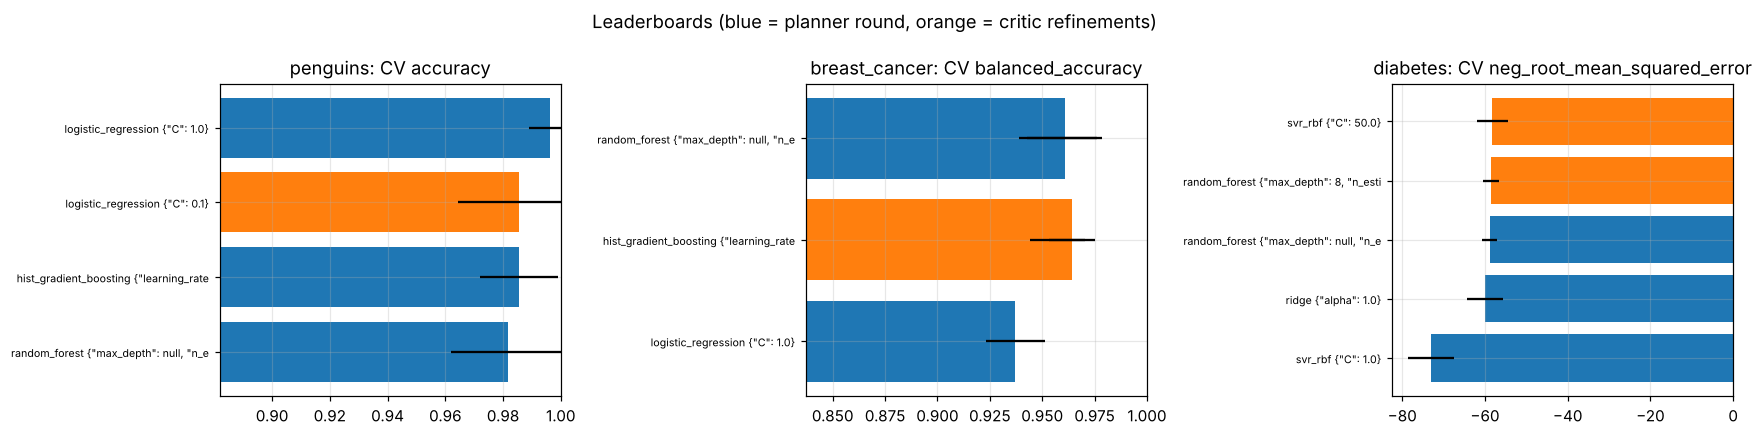

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (n, st) in zip(axes, runs.items()):
    lb = st["leaderboard"].dropna(subset=["cv_mean"]).sort_values("cv_mean")
    labels = [f"{m} {p}"[:38] for m, p in zip(lb.model, lb.params)]
    colors = ["tab:orange" if r == 2 else "tab:blue" for r in lb["round"]]
    ax.barh(labels, lb.cv_mean, xerr=lb.cv_std, color=colors)
    ax.set(title=f"{n}: CV {st['final']['metric']}", xlim=(max(0, lb.cv_mean.min() - 0.1), min(1.0, lb.cv_mean.max() + 0.05)) if st['spec']['task'] == 'classification' else None)
    ax.tick_params(axis="y", labelsize=7)
fig.suptitle("Leaderboards (blue = planner round, orange = critic refinements)")
plt.tight_layout(); plt.show()
allb = pd.concat([st["leaderboard"].assign(dataset=n) for n, st in runs.items()])
px.scatter(allb, x="fit_seconds", y="cv_mean", color="model", facet_col="dataset", hover_data=["params", "gap"],
           title="CV score vs fit time (interactive)").write_html(OUT / "leaderboards.html", include_plotlyjs="cdn")

**How to read the results**

* **Selection is honest.** Models are compared only on cross-validation within the training split; the test set is touched once, for the final model. The "untuned linear" and "trivial" rows show whether the agent's search added value.
* The **critic round** (orange) shows the refine step at work: some refinements improve on the planner's choices and others confirm them. Both are useful outcomes of an experiment loop.
* On small, clean benchmarks such as these, strong defaults are hard to beat. Differences of a point or two between the agent's choice and a tuned linear model are often within cross-validation noise (see the ± columns). The agent's value lies less in squeezing out accuracy than in **automating a disciplined, auditable process**: profiling, leakage checks, consistent preprocessing inside folds, documented decisions and a model card.

**Limitations.** The registry is intentionally small. Search is a few configurations rather than full Bayesian optimisation, and there is no feature engineering. The LLM's planning quality depends on the backend; with a small local model, the validation layer often fills in defaults. Extensions include Optuna-backed search inside the experimenter tool, SHAP explanations in the model card, and fairness checks.

In [14]:
llm.report()

LLM provenance for this run
  huggingface/Qwen/Qwen3-1.7B: no API key and no Ollama server: running offline with a local Hugging Face model; best Apache-2.0 model that fits 7.4 GB free cpu memory
  LIVE  huggingface/Qwen/Qwen3-1.7B: 9 calls, 2935 in / 928 out tokens, 177s, $0 (local)
  live calls: 9 | replayed from cache: 0 | retries: 0 | fallbacks: 0


{'provider': 'huggingface',
 'model': 'Qwen/Qwen3-1.7B',
 'revision': None,
 'selection': 'no API key and no Ollama server: running offline with a local Hugging Face model; best Apache-2.0 model that fits 7.4 GB free cpu memory',
 'cache_mode': 'off',
 'stats': {'calls': 9,
  'live_calls': 9,
  'cache_hits': 0,
  'seconds': 176.5440216064453,
  'input_tokens': 2935,
  'output_tokens': 928,
  'retries': 0,
  'fallbacks': 0,
  'errors': 0},
 'events': [],
 'python': '3.13.18',
 'by_source': [{'provider': 'huggingface',
   'model': 'Qwen/Qwen3-1.7B',
   'source': 'live',
   'calls': 9,
   'input_tokens': 2935,
   'output_tokens': 928,
   'seconds': 176.544,
   'est_cost_usd': 0.0,
   'errors': 0}]}